# 01 — Synthetic Data Generation

This notebook generates the **training dataset** for Clarity's efficiency regressor and RL
assignment agent. It does not train any model — that lives in notebooks 03 and 04.

All simulation logic is implemented as importable Python modules in
`backend/app/ml/simulation/`. This notebook is documentation + orchestration only:
it sets configuration, calls the simulator, runs sanity checks, and writes the dataset to
`backend/app/ml/data/synthetic/`.

**Why this design?** Notebook cells are great for exploration but terrible for code reuse.
Putting the dataclasses, generators, noise model, and Simulator behind a real package means
every later notebook (validation, regressor training, RL training) imports the *same*
implementation, and the production FastAPI service can later import these abstractions too.

## 1 · Setup

Add `backend/` to `sys.path` so we can import `app.ml.simulation.*`. We do **not** rely on
the project being `pip install`-ed — the notebook works from a fresh clone.

In [14]:
import os, sys, warnings, logging
from pathlib import Path

# Suppress HF / sentence-transformers noise in NLP mode.
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.simplefilter("ignore")
for _name in ("huggingface_hub", "sentence_transformers", "transformers"):
    logging.getLogger(_name).setLevel(logging.ERROR)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BACKEND_DIR = PROJECT_ROOT / "backend"
if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from app.ml.simulation import (
    LogNormalNoise,
    Simulator,
    TaskGenerator,
    WorkerGenerator,
    CANONICAL_CATEGORIES,
)
from app.ml.nlp import SemanticEncoder, sim_worker_to_text

NLP_CACHE = PROJECT_ROOT / "backend" / "app" / "ml" / "data" / "nlp" / "task_embeddings_cache.npy"
print("Project root:", PROJECT_ROOT)
print("Categories:", CANONICAL_CATEGORIES)
if NLP_CACHE.exists():
    print(f"NLP cache: {NLP_CACHE.name}  ({NLP_CACHE.stat().st_size / 1024 / 1024:.1f} MB)")
else:
    print("NLP cache: NOT FOUND — run notebook 00 first")

Project root: C:\Projects\Clarity
Categories: ('backend', 'frontend', 'devops', 'design', 'mobile', 'data', 'qa', 'security')
NLP cache: task_embeddings_cache.npy  (58.2 MB)


## 2 · Configuration

Every tweakable knob lives in this cell. Re-running this notebook with a different `SEED`
or `N_EPISODES` does not require touching any other cell.

In [15]:
N_EPISODES = 500          # one episode = one simulated sprint
SEED = 42                 # master seed; every stochastic decision derives from it
TEAM_SIZE_RANGE = (4, 12) # min/max workers per sprint (typical single-team range)
SIGMA_MULTIPLIER = 1.0    # baseline noise level; notebook 02 sweeps {0.5, 1.0, 2.0}

DATA_DIR = PROJECT_ROOT / "backend" / "app" / "ml" / "data" / "synthetic"
DATA_DIR.mkdir(parents=True, exist_ok=True)
PARQUET_PATH = DATA_DIR / "dataset.parquet"
CSV_PATH = DATA_DIR / "dataset.csv"

print("Output dir:", DATA_DIR)

Output dir: C:\Projects\Clarity\backend\app\ml\data\synthetic


## 3 · NLP-aware data generation

Generates a second dataset where tasks carry real Jira titles/descriptions (from the
story-points corpus) and workers carry generated text descriptions. Skill match is
computed as rescaled cosine similarity between embeddings rather than a category lookup.

The legacy generation in Section 4 is unchanged — this section is additive only.


In [16]:
encoder = SemanticEncoder()
print(f"Encoder loaded: dim={encoder.dim}")


Encoder loaded: dim=384


In [17]:
task_gen   = TaskGenerator()
worker_gen = WorkerGenerator()
sim_nlp    = Simulator(seed=42)

rows_nlp = sim_nlp.run_sprints(
    n_sprints=200,
    workers_per_sprint=(4, 12),
    tasks_per_sprint=(15, 60),
    task_generator=task_gen,
    worker_generator=worker_gen,
    use_nlp=True,
    encoder=encoder,
)

df_nlp = pd.DataFrame(rows_nlp)
print(f"NLP dataset shape: {df_nlp.shape}")
print(df_nlp.dtypes)


NLP dataset shape: (7613, 18)
complexity                    int64
priority_numeric              int64
estimated_minutes_norm      float64
requires_min_seniority        int64
seniority_numeric             int64
years_experience_norm       float64
base_productivity           float64
load_ratio_at_assignment    float64
historical_efficiency       float64
actual_minutes              float64
efficiency_ratio            float64
worker_id                     int64
task_id                       int64
task_category                object
was_blocked                    bool
sprint_id                     int64
skill_match_score           float64
is_strong_match               int64
dtype: object


In [18]:
# Schema check — confirm new columns present and legacy columns absent.
assert "skill_match_score" in df_nlp.columns, "skill_match_score missing"
assert "is_strong_match" in df_nlp.columns, "is_strong_match missing"
assert "category_backend" not in df_nlp.columns, "category_backend should be absent in NLP mode"
assert "proficiency_for_task_category" not in df_nlp.columns, "legacy proficiency column should be absent"
print("Schema OK")
print(df_nlp[["skill_match_score", "is_strong_match", "efficiency_ratio"]].describe())


Schema OK
       skill_match_score  is_strong_match  efficiency_ratio
count        7613.000000      7613.000000       7613.000000
mean            0.687567         0.612242          1.457403
std             0.345284         0.487271          0.766143
min             0.000000         0.000000          0.332659
25%             0.424163         0.000000          0.936391
50%             0.815099         1.000000          1.214133
75%             1.000000         1.000000          1.752671
max             1.000000         1.000000          7.304133


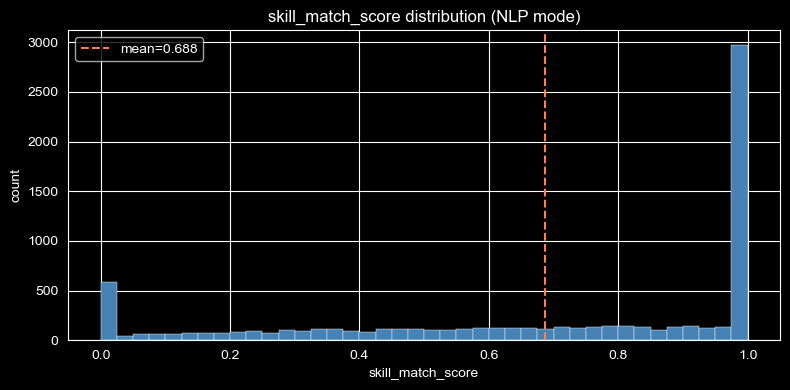

Score range looks healthy: 5th pct=0.000, 95th pct=1.000


In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
df_nlp["skill_match_score"].hist(bins=40, ax=ax, color="steelblue", edgecolor="white", linewidth=0.3)
ax.set_title("skill_match_score distribution (NLP mode)")
ax.set_xlabel("skill_match_score")
ax.set_ylabel("count")
ax.axvline(df_nlp["skill_match_score"].mean(), color="coral", linestyle="--",
           label=f"mean={df_nlp['skill_match_score'].mean():.3f}")
ax.legend()
plt.tight_layout()
plt.show()

# The rescaling should spread scores across [0, 1]. Warn if they're still compressed.
lo, hi = df_nlp["skill_match_score"].quantile(0.05), df_nlp["skill_match_score"].quantile(0.95)
if hi - lo < 0.4:
    print(f"WARNING: scores still compressed — 5th–95th pct range is only {hi - lo:.3f}. "
          "Consider adjusting the rescaling bounds in Simulator._simulate_actual_minutes().")
else:
    print(f"Score range looks healthy: 5th pct={lo:.3f}, 95th pct={hi:.3f}")


In [20]:
corr = df_nlp[["skill_match_score", "efficiency_ratio"]].corr()
print("Correlation matrix:")
print(corr.to_string())

r = corr.loc["skill_match_score", "efficiency_ratio"]
if abs(r) < 0.05:
    print(f"\nWARNING: correlation is near zero ({r:.3f}). "
          "skill_match_score may not be driving the efficiency formula correctly. "
          "Check the rescaling logic in Simulator._simulate_actual_minutes().")
elif r < 0:
    print(f"\nExpected negative correlation observed (r={r:.3f}): "
          "higher skill match → faster completion. ✓")
else:
    print(f"\nPositive correlation (r={r:.3f}) — unexpected. "
          "Inspect the proficiency-to-skill_multiplier mapping.")


Correlation matrix:
                   skill_match_score  efficiency_ratio
skill_match_score           1.000000         -0.732961
efficiency_ratio           -0.732961          1.000000

Expected negative correlation observed (r=-0.733): higher skill match → faster completion. ✓


## 3b · Feature list (NLP schema)

Defines the columns used for model training in NLP mode. Compared to the legacy schema:
- **Removed**: 8 `category_*` one-hot columns, `proficiency_for_task_category`, `is_primary_specialisation`
- **Added**: `skill_match_score` (continuous), `is_strong_match` (binary threshold at 0.65)


In [21]:
FEATURES = [
    "complexity",
    "priority_numeric",
    "estimated_minutes_norm",
    "requires_min_seniority",
    "seniority_numeric",
    "years_experience_norm",
    "skill_match_score",      # replaces: category_* one-hot + proficiency_for_task_category
    "is_strong_match",        # replaces: is_primary_specialisation
    "base_productivity",
    "load_ratio_at_assignment",
    "historical_efficiency",
]
print("NLP feature columns:", FEATURES)


NLP feature columns: ['complexity', 'priority_numeric', 'estimated_minutes_norm', 'requires_min_seniority', 'seniority_numeric', 'years_experience_norm', 'skill_match_score', 'is_strong_match', 'base_productivity', 'load_ratio_at_assignment', 'historical_efficiency']


## 3 · Generation

Construct the simulator with a `LogNormalNoise` strategy (Open/Closed: swap to a different
`BaseNoiseStrategy` subclass to change the noise model with zero edits to `Simulator`).
Then generate the full dataset: one row per completed assignment, across all sprints.

In [22]:
noise = LogNormalNoise(sigma_multiplier=SIGMA_MULTIPLIER)
simulator = Simulator(
    noise_strategy=noise,
    team_size_range=TEAM_SIZE_RANGE,
    worker_generator=WorkerGenerator(),
    task_generator=TaskGenerator(),
)

df = simulator.run_dataset(n_episodes=N_EPISODES, seed=SEED)
print(f"Generated {len(df):,} assignment rows across {N_EPISODES} sprints")
df.head()

Generated 17,873 assignment rows across 500 sprints


,complexity,priority_numeric,estimated_minutes_norm,requires_min_seniority,seniority_numeric,years_experience_norm,base_productivity,load_ratio_at_assignment,historical_efficiency,actual_minutes,...,category_backend,category_frontend,category_devops,category_design,category_mobile,category_data,category_qa,category_security,proficiency_for_task_category,is_primary_specialisation
0,3,4,0.302083,0,0,0.05,1.020150,0.000000,NaN,325.870524,...,0,0,0,0,0,1,0,0,0.194871,0
1,4,4,1.000000,2,0,0.00,1.195131,0.000000,NaN,1869.329470,...,1,0,0,0,0,0,0,0,0.162697,0
2,4,4,0.804167,0,1,0.25,0.987756,0.000000,NaN,706.562040,...,0,0,0,0,1,0,0,0,0.196658,0
3,3,4,0.485417,1,0,0.05,1.020150,0.072283,NaN,435.515070,...,0,0,0,0,1,0,0,0,0.278013,0
4,1,4,0.081250,0,0,0.05,1.020150,0.188435,NaN,54.434917,...,0,0,0,0,0,0,1,0,0.507708,0


In [23]:
df.describe()

,complexity,priority_numeric,estimated_minutes_norm,requires_min_seniority,seniority_numeric,years_experience_norm,base_productivity,load_ratio_at_assignment,historical_efficiency,actual_minutes,...,category_backend,category_frontend,category_devops,category_design,category_mobile,category_data,category_qa,category_security,proficiency_for_task_category,is_primary_specialisation
count,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,107.000000,17873.000000,...,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000,17873.000000
mean,2.546579,2.998098,0.373202,0.572875,0.938287,0.241459,1.011388,0.223188,1.719724,462.975289,...,0.121132,0.127567,0.125776,0.126448,0.126336,0.122755,0.124378,0.125608,0.380115,0.125944
std,1.120121,0.897186,0.312746,0.825380,0.890519,0.204381,0.154088,0.261589,0.521339,728.197922,...,0.326290,0.333616,0.331606,0.332363,0.332237,0.328165,0.330021,0.331417,0.205664,0.331796
min,1.000000,1.000000,0.020833,0.000000,0.000000,0.000000,0.599610,0.000000,0.816353,10.274046,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.150048,0.000000
25%,2.000000,2.000000,0.139583,0.000000,0.000000,0.100000,0.903217,0.000000,1.319145,100.933948,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.226934,0.000000
50%,2.000000,3.000000,0.262500,0.000000,1.000000,0.200000,0.997258,0.112326,1.771149,218.409543,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.309644,0.000000
75%,3.000000,4.000000,0.491667,1.000000,2.000000,0.350000,1.103386,0.370874,1.963917,474.369440,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.495117,0.000000
max,5.000000,5.000000,1.000000,3.000000,3.000000,1.000000,1.745120,0.989996,3.943416,9910.639046,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.999765,1.000000


## 4 · Quick sanity checks

Surface the kind of issue that silently corrupts a regressor: class imbalance, unexpected
nulls, or efficiency_ratio values outside any plausible range. We *flag* — we don't fix
here. Real validation lives in notebook 02.

In [24]:
print("== Category balance (task_category) ==")
print(df["task_category"].value_counts(normalize=True).round(3).to_string())

print("\n== Complexity distribution ==")
print(df["complexity"].value_counts().sort_index().to_string())

print("\n== Priority distribution (priority_numeric: 5=P1, 1=P5) ==")
print(df["priority_numeric"].value_counts().sort_index().to_string())

print("\n== Seniority of assigned workers ==")
print(df["seniority_numeric"].value_counts().sort_index().to_string())

print("\n== Null counts (only non-zero shown) ==")
nulls = df.isna().sum()
nulls = nulls[nulls > 0]
print(nulls.to_string() if len(nulls) else "(none beyond historical_efficiency cold-start)")

print("\n== efficiency_ratio summary ==")
er = df["efficiency_ratio"]
print(f"min={er.min():.3f}  median={er.median():.3f}  mean={er.mean():.3f}  max={er.max():.1f}")
if (er <= 0).any():
    print("!! WARNING: non-positive efficiency_ratio found")
if er.max() > 200:
    print(f"!! WARNING: extreme upper tail (max={er.max():.0f}) — inspect blocking mechanic")

print("\n== Blocking rate ==")
print(f"{df['was_blocked'].mean():.1%} of assignments were blocked")

== Category balance (task_category) ==
task_category
frontend    0.128
design      0.126
mobile      0.126
devops      0.126
security    0.126
qa          0.124
data        0.123
backend     0.121

== Complexity distribution ==
complexity
1    3605
2    5356
3    5380
4    2602
5     930

== Priority distribution (priority_numeric: 5=P1, 1=P5) ==
priority_numeric
1     903
2    3599
3    8902
4    3567
5     902

== Seniority of assigned workers ==
seniority_numeric
0    6723
1    6479
2    3722
3     949

== Null counts (only non-zero shown) ==
historical_efficiency    17766

== efficiency_ratio summary ==
min=0.425  median=1.733  mean=1.860  max=10.8

== Blocking rate ==
9.6% of assignments were blocked


## 5 · Export

Write parquet (compact + typed) and CSV (human-inspectable). Both are gitignored — the
notebooks regenerate them deterministically from `SEED`.

In [25]:
import json

# Legacy dataset.
df.to_parquet(PARQUET_PATH, index=False)
df.to_csv(CSV_PATH, index=False)
print(f"Wrote {PARQUET_PATH.name}: {PARQUET_PATH.stat().st_size / 1024:.1f} KB")
print(f"Wrote {CSV_PATH.name}: {CSV_PATH.stat().st_size / 1024:.1f} KB")
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")

# NLP dataset.
nlp_parquet = DATA_DIR / "synthetic_nlp.parquet"
df_nlp.to_parquet(nlp_parquet, index=False)
print(f"\nWrote {nlp_parquet.name}: {nlp_parquet.stat().st_size / 1024:.1f} KB")
print(f"NLP rows: {len(df_nlp):,} | Columns: {len(df_nlp.columns)}")

# Feature list for NLP regressor training (notebook 03).
features_path = DATA_DIR / "features_nlp.json"
features_path.write_text(json.dumps(FEATURES, indent=2))
print(f"Wrote {features_path.name}")


Wrote dataset.parquet: 779.9 KB
Wrote dataset.csv: 2757.2 KB
Rows: 17,873 | Columns: 26

Wrote synthetic_nlp.parquet: 306.0 KB
NLP rows: 7,613 | Columns: 18
Wrote features_nlp.json


## 6 · Verification

Self-checks that catch schema drift and legacy regression silently.


In [26]:
# 1. NLP dataset is not empty.
assert len(df_nlp) > 0, "No rows generated"

# 2. All FEATURES present in dataset.
missing = [f for f in FEATURES if f not in df_nlp.columns]
assert not missing, f"Missing feature columns: {missing}"

# 3. No NaN in features or target (historical_efficiency is allowed NaN — it's metadata).
check_cols = [f for f in FEATURES if f != "historical_efficiency"] + ["efficiency_ratio"]
nan_counts = df_nlp[check_cols].isna().sum()
nan_found = nan_counts[nan_counts > 0]
assert nan_found.empty, f"NaN found in features:\n{nan_found}"

# 4. skill_match_score in [0, 1].
assert df_nlp["skill_match_score"].between(0, 1).all(), \
    f"skill_match_score out of [0,1]: {df_nlp['skill_match_score'].describe()}"

# 5. NLP package still importable.
from app.ml.nlp import SemanticEncoder, skill_match, task_to_text, sim_worker_to_text
print("NLP package OK")

# 6. Legacy mode regression guard — original schema must be intact.
legacy_sim = Simulator()
legacy_rows = legacy_sim.run_sprints(
    n_sprints=5,
    workers_per_sprint=(4, 8),
    tasks_per_sprint=(10, 20),
    use_nlp=False,
)
df_legacy = pd.DataFrame(legacy_rows)
assert "category_backend" in df_legacy.columns, "Legacy schema broken — category_backend missing"
assert "proficiency_for_task_category" in df_legacy.columns, "Legacy schema broken"
assert "skill_match_score" not in df_legacy.columns, "NLP column leaked into legacy schema"
print("Legacy mode regression guard OK")

# 7. Imports sanity.
from app.ml.simulation.simulator import Simulator as _S
from app.ml.simulation.generator import TaskGenerator as _TG, WorkerGenerator as _WG
print("\nAll imports OK")
print("All checks passed.")


NLP package OK
Legacy mode regression guard OK

All imports OK
All checks passed.
